In [1]:
import pandas as pd
import numpy as np
import xarray as xr
import os
import matplotlib.pyplot as plt
import json

from utils_wind_analysis import get_wind_direction_in_degrees, get_wind_speed

In [2]:
lake = 'lucerne'
base_folder = rf'/home/leroquan@eawag.wroot.emp-eaw.ch/work_space/{lake}_100m_2025'

In [3]:
grid_folder = os.path.join(base_folder, 'grid')
with open(os.path.join(grid_folder, 'parameters.json'), 'r') as file:
    grid_angle = json.load(file)["rotation"]

In [4]:
bin_folder = os.path.join(base_folder, 'binary_data')

In [5]:
base_output_folder = rf"/storage/alplakes_test/{lake}_100m_2025"
output_folder = os.path.join(base_output_folder, 'wind_analysis')
os.makedirs(output_folder, exist_ok=True)

# Import xarray wind

In [6]:
ds = xr.open_dataset(os.path.join(bin_folder, 'wind.nc'))

In [19]:
ds2 = xr.open_dataset(os.path.join(base_folder+'_2', 'binary_data', 'wind.nc'))

In [24]:
ds = xr.concat([ds, ds2], dim='time')

# Define zones

In [25]:
zone_map = {}
zone_coord = {}

if lake == 'lucerne':
    zone_map = {
        0: "alt",
        1: "ges",
        2: "luz",
        3: "alpnachsee",
    }
    zone_coord = {'luz':[[(0,100),(0,180)],
                        [(100,120),(85,130)],
                        [(120,145),(91,130)],
                        [(145,150),(95,130)]],
                'ges':[[(100,230),(0,180)]],
                'alt':[[(230,288),(0,180)]],
                'alpnachsee':[[(0,52),(0,38)]]}

In [26]:
arr_zones = np.zeros((int(len(ds.y)),int(len(ds.x))))
for idx, sta_name in zone_map.items():
    for zones in zone_coord[sta_name]:
        arr_zones[zones[1][0]:zones[1][1],zones[0][0]:zones[0][1]] = idx

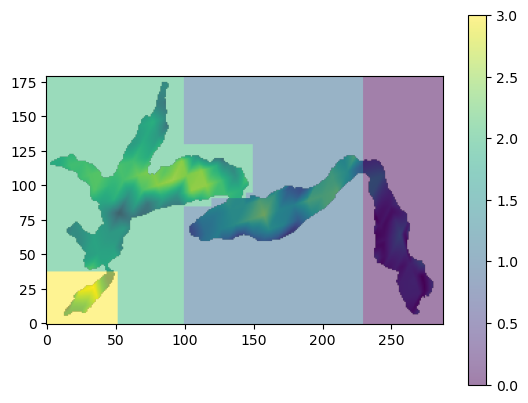

In [27]:
plt.imshow(ds.speed.isel(time=0).values, origin='lower')
plt.imshow(arr_zones, origin='lower', alpha=0.5)
plt.colorbar()

# Statistics per zone

In [28]:
def compute_mean_characteristics(ds, zone_name):
    u_mean = ds.u10.mean(dim=["x", "y"])
    v_mean = ds.v10.mean(dim=["x", "y"])
    speed_mean = ds.speed.mean(dim=["x", "y"])

    dvdx = ds.v10.differentiate("x")
    dudy = ds.u10.differentiate("y")
    vorticity = dvdx - dudy
    vorticity_mean = vorticity.mean(dim=["x", "y"])
    vorticity_strength = np.abs(vorticity).mean(dim=["x", "y"])

    direction_mean = get_wind_direction_in_degrees(
        u_mean, v_mean, grid_angle
    )
    direction_mean.name = "direction"

    # add zone dimension
    u_mean = u_mean.expand_dims(zone=[zone_name])
    v_mean = v_mean.expand_dims(zone=[zone_name])
    speed_mean = speed_mean.expand_dims(zone=[zone_name])
    direction_mean = direction_mean.expand_dims(zone=[zone_name])
    vorticity_mean = vorticity_mean.expand_dims(zone=[zone_name])
    vorticity_strength = vorticity_strength.expand_dims(zone=[zone_name])

    ds_mean = xr.Dataset(
        data_vars={
            "u10": u_mean,
            "v10": v_mean,
            "speed": speed_mean,
            "direction": direction_mean,
            "vorticity_mean": vorticity_mean,
            "vorticity_strength": vorticity_strength,
        }
    )

    return ds_mean

In [29]:
ds_zone_list = []
ds_zone_list.append(compute_mean_characteristics(ds, 'all')) # First the entire lake

for zone_id, zone_name in zone_map.items():
    ds_zone = ds.where(arr_zones == zone_id)
    ds_mean_zone = compute_mean_characteristics(ds_zone, zone_name)
    ds_zone_list.append(ds_mean_zone)

In [30]:
# Concat ds
ds_mean_all = xr.concat(ds_zone_list, dim="zone")

In [31]:
def get_cardinal_direction(degrees):
    directions = np.array(["N", "E", "S", "W"])
    valid = np.isfinite(degrees)
    angles = np.where(valid, degrees, 0) % 360
    indices = ((angles + 45) // 90).astype(int) % 4
    return np.where(valid, directions[indices], "")

cardinal_direction = xr.apply_ufunc(
    get_cardinal_direction,
    ds_mean_all.direction,
    dask="parallelized",
    output_dtypes=[np.dtype("<U2")],
)

In [32]:
cardinal_direction.time

<xarray.DataArray 'time' (time: 10202)> Size: 82kB
array(['2025-01-01T00:00:00.000000000', '2025-01-01T01:00:00.000000000',
       '2025-01-01T02:00:00.000000000', ..., '2026-02-28T22:00:00.000000000',
       '2026-02-28T23:00:00.000000000', '2026-03-01T00:00:00.000000000'],
      shape=(10202,), dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 82kB 2025-01-01 ... 2026-03-01

In [33]:
ds_mean_all['direction_cardinal'] = cardinal_direction

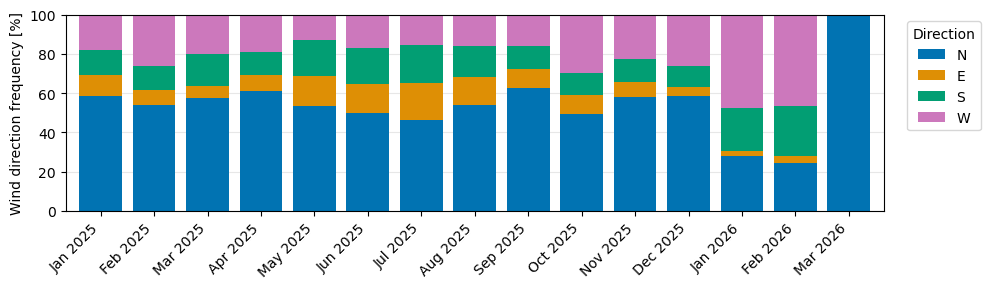

In [34]:
# Convert zone 0 to a DataFrame (assuming the time dimension is "time")
df = (
    cardinal_direction.isel(zone=0)
    .to_series()
    .rename("direction")
    .reset_index()
)

# Exclude missing directions
df = df[df["direction"].isin(["N", "E", "S", "W"])]
df["month"] = df["time"].dt.to_period("M")

# Monthly counts and percentages
counts = (
    pd.crosstab(df["month"], df["direction"])
    .reindex(columns=["N", "E", "S", "W"], fill_value=0)
    .sort_index()
)
percentages = counts.div(counts.sum(axis=1), axis=0) * 100

# Plot
ax = percentages.plot.bar(
    stacked=True,
    figsize=(10, 3),
    color=["#0173B2", "#DE8F05", "#029E73", "#CC78BC"],
    width=0.8,
)

ax.set_xticklabels(
    [month.strftime("%b %Y") for month in percentages.index],
    rotation=45,
    ha="right",
)
ax.set_xlabel("")
ax.set_ylabel("Wind direction frequency [%]")
ax.set_ylim(0, 100)
ax.legend(title="Direction", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [35]:
ds_mean_all.to_netcdf(os.path.join(output_folder, "wind_stats.nc"))

## Speed

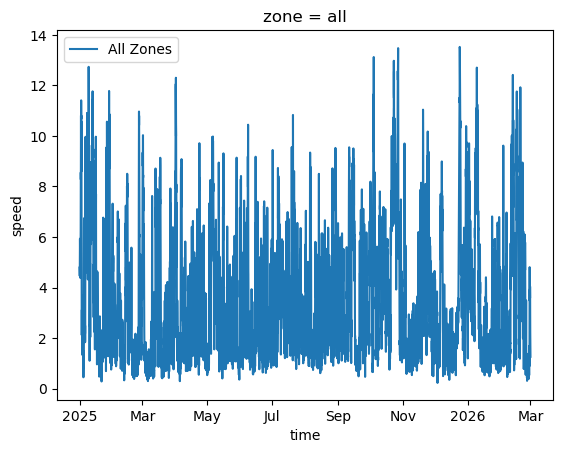

In [27]:
for idx, sta_name in zone_map.items():
    ds_mean_all.speed.isel(zone=idx).plot(label=sta_name)
ds_mean_all.speed.sel(zone='all').plot(label='All Zones')
plt.legend()

## Vorticity

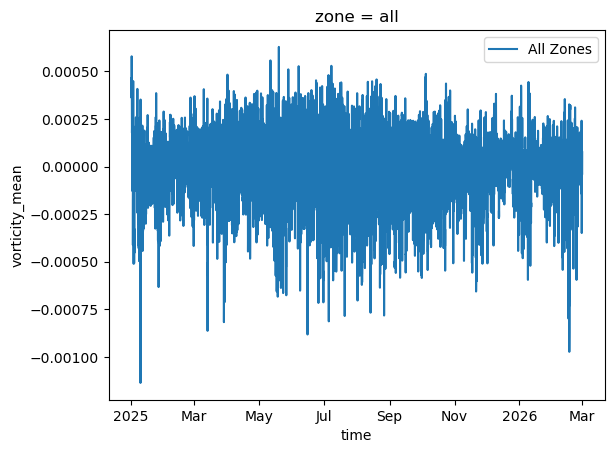

In [28]:
for idx, sta_name in zone_map.items():
    ds_mean_all.vorticity_mean.isel(zone=idx).plot(label=sta_name)
ds_mean_all.vorticity_mean.sel(zone='all').plot(label='All Zones')
plt.legend()

In [ ]:
plt.figure(figsize=(15,7))
sta_name = 'luz'
ds_mean_all.vorticity_mean.sel(zone=sta_name).plot(label='Mean')
ds_mean_all.vorticity_strength.sel(zone=sta_name).plot(label='Strength')
plt.legend()
plt.title(f'Zone = {sta_name}')